In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [2]:
df.sample(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
1054061,1163839,B0C2HH89QM,NIVIAN -4G Bullet Surveillance Camera (SIM) + ...,4.6,6,125.68,False,0,Surveillance Cameras
2290967,2643960,B00VJQAW3O,"Powery Battery for Garmin type 361-00051-02, 3...",4.0,6,12.50,False,0,"GPS, Finders & Accessories"
1477269,1634008,B0C6K66WNJ,NHNKB T-Shirt Women's Blouses & Tunics For Wom...,0.0,0,8.95,False,0,Sports & Outdoors
2627,2803,B079K1897V,KSS213F Replacement Sony Laser / Optical Unit ...,5.0,1,9.99,False,0,"CD, Disc & Tape Players"
1613456,1815539,B09M3P7TYX,Jouseer 8 Pieces A4 Colour Overlay For Dyslexi...,4.5,42,10.99,False,0,Professional Education Supplies


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body and Birthday Gifts.


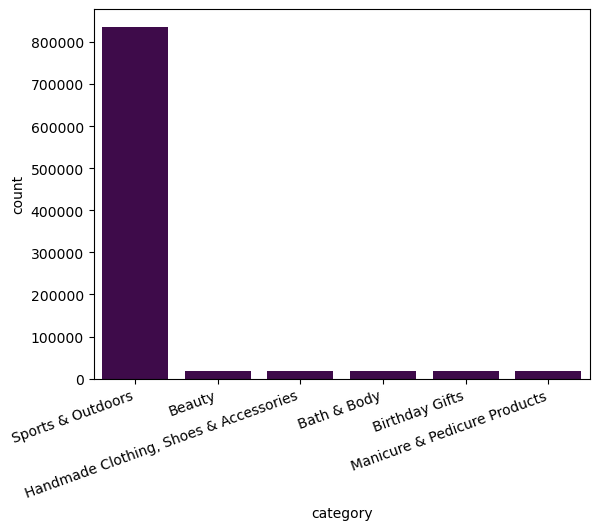

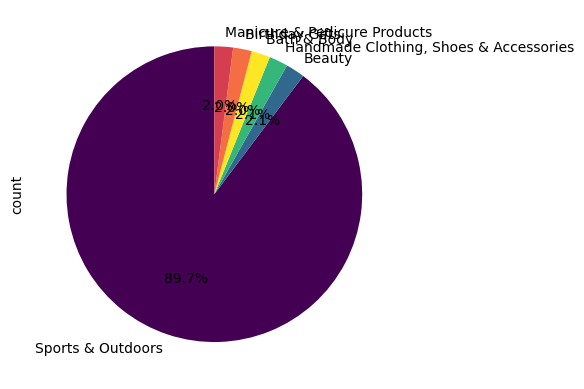

Sports & Outdoors dominates the listings


In [3]:
### Part 1: Understanding Product Categories

## **Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
## 
## 1. **Frequency Tables**:
##     - Generate a frequency table for the product `category`.
display(df.category.value_counts())
freq_table = df.category.value_counts()

##     - Which are the top 5 most listed product categories?
print('Sports & Outdoors, Beauty, Handmade Clothing, Shoes & Accessories, Bath & Body and Birthday Gifts.')

## 2. **Visualizations**:
##     - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
sns.barplot(data=freq_table.iloc[:6], color= '#440154FF')
plt.xticks(rotation=20, ha='right')
plt.show()

##     - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
freq_table.iloc[:6].plot.pie(autopct='%1.1f%%', startangle=90, colors=['#440154', '#31688E', '#35B779', '#FDE725', '#F46D43', '#D53E4F'])
plt.show()

print('Sports & Outdoors dominates the listings')

Price median: 19.09
---------------------------------------------------------------------------------
Price mean: 89.24
---------------------------------------------------------------------------------
Price mode: 0    9.99
Name: price, dtype: float64
---------------------------------------------------------------------------------
£89.24 is the average price, which is 10 times the most common price (mode)
---------------------------------------------------------------------------------
Price variance: 119445.49
---------------------------------------------------------------------------------
Price std deviation: 345.61
---------------------------------------------------------------------------------
Price range: 100000.0
---------------------------------------------------------------------------------
Price interquantile range: 36.0
---------------------------------------------------------------------------------
The price distribution is very spread. We can see a first indication in 

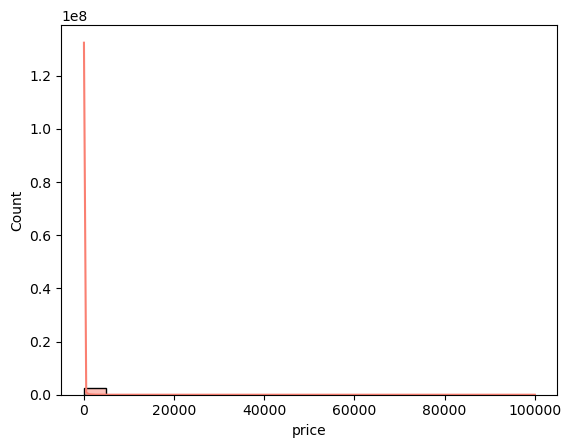

It is indeed hard to visualise because of the high spread of the data.
      A solution would be to cap the plot, or to remove the very high prices.(>5000, outliers)
---------------------------------------------------------------------------------


<Axes: xlabel='price'>

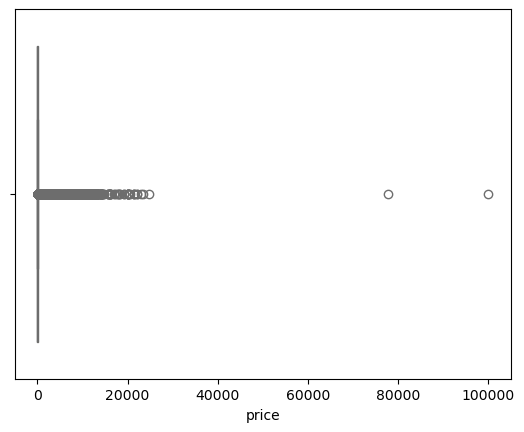

In [7]:
## ### Part 2: Delving into Product Pricing
## 
## **Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
## 
## 1. **Measures of Centrality**:
##     - Calculate the mean, median, and mode for the `price` of products.
print(f'Price median: {df['price'].median()}\n---------------------------------------------------------------------------------')
print(f'Price mean: {round(df['price'].mean(), 2)}\n---------------------------------------------------------------------------------')
print(f'Price mode: {df['price'].mode()}\n---------------------------------------------------------------------------------')
##     - What's the average price point of products listed? How does this compare with the most common price point (mode)?
print('£89.24 is the average price, which is 10 times the most common price (mode)\n---------------------------------------------------------------------------------')
## 2. **Measures of Dispersion**:
##     - Determine the variance, standard deviation, range, and interquartile range for product `price`.
print(f'Price variance: {round(df['price'].var(), 2)}\n---------------------------------------------------------------------------------')
print(f'Price std deviation: {round(df['price'].std(), 2)}\n---------------------------------------------------------------------------------')
print(f'Price range: {df['price'].max() - df['price'].min()}\n---------------------------------------------------------------------------------')
print(f'Price interquantile range: {df['price'].quantile(0.75) - df['price'].quantile(0.25)}\n---------------------------------------------------------------------------------')
##     - How varied are the product prices? Are there any indicators of a significant spread in prices?
print("""The price distribution is very spread. We can see a first indication in the 
difference between median and mean price. The mode is also lower than both median and mean.
The standard deviation being over 3 times the average price also indicates high dispersion.
We can deduce from the interquantile range that the core of the price distribution is between 
£30-40, while a few very high prices inflate the other metrics.\n---------------------------------------------------------------------------------""")
## 3. **Visualizations**:
##     - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
sns.histplot(df['price'], kde=True, bins=20, color='salmon')
plt.show()
print("""It is indeed hard to visualise because of the high spread of the data.
A solution would be to cap the plot, or to remove the very high prices.(>5000, outliers)\n---------------------------------------------------------------------------------""")

##     - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 
sns.boxplot(data = df['price'], color="salmon", orient='h')
print("""We can see from the box plot how many values fall into the outliers category.)\n---------------------------------------------------------------------------------""")

Rating median: 0.0
---------------------------------------------------------------------------------
Rating mean: 2.15
---------------------------------------------------------------------------------
Rating mode: 0    0.0
Name: stars, dtype: float64
---------------------------------------------------------------------------------
Most customers don't rate products. Hence why the mode and median are 0. This 
affects the average value, even though many items are highly rated, the mean is 
pushed down to 2.15
---------------------------------------------------------------------------------
Rating variance: 4.82
---------------------------------------------------------------------------------
Rating std deviation: 2.19
---------------------------------------------------------------------------------
Rating interquantile range: 4.4
---------------------------------------------------------------------------------
There is a wide variation between customer feedback. The standard deviation
is

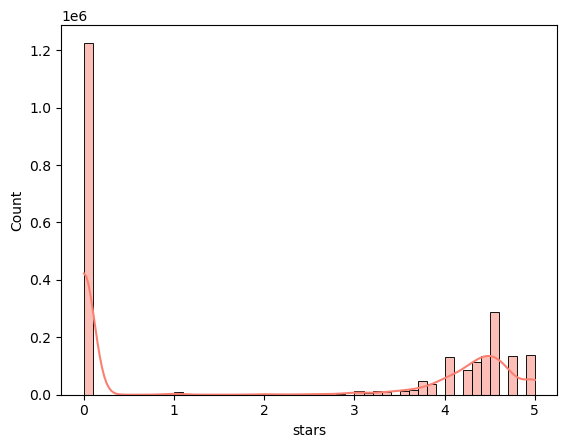

In [ ]:
## ### Part 3: Unpacking Product Ratings
## 
## **Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?
## 
## 1. **Measures of Centrality**:
##     - Calculate the mean, median, and mode for the `rating` of products.
print(f'Rating median: {df['stars'].median()}\n---------------------------------------------------------------------------------')
print(f'Rating mean: {round(df['stars'].mean(), 2)}\n---------------------------------------------------------------------------------')
print(f'Rating mode: {df['stars'].mode()}\n---------------------------------------------------------------------------------')

##     - How do customers generally rate products? Is there a common trend?
print("""Most customers don't rate products. Hence why the mode and median are 0. This 
affects the average value, even though many items are highly rated, the mean is 
pushed down to 2.15\n---------------------------------------------------------------------------------""")


## 2. **Measures of Dispersion**:
##     - Determine the variance, standard deviation, and interquartile range for product `rating`.
print(f'Rating variance: {round(df['stars'].var(), 2)}\n---------------------------------------------------------------------------------')
print(f'Rating std deviation: {round(df['stars'].std(), 2)}\n---------------------------------------------------------------------------------')
print(f'Rating interquantile range: {df['stars'].quantile(0.75) - df['stars'].quantile(0.25)}\n---------------------------------------------------------------------------------')

##     - Are the ratings consistent, or is there a wide variation in customer feedback?
print("""There is a wide variation between customer feedback. The standard deviation
is as high as the average value.\n---------------------------------------------------------------------------------""")


## 3. **Shape of the Distribution**:
##     - Calculate the skewness and kurtosis for the `rating` column. 
print(f'Rating skewness: {round(df['stars'].skew(), 2)}\n---------------------------------------------------------------------------------')
print(f'Rating skewness: {round(df['stars'].kurt(), 2)}\n---------------------------------------------------------------------------------')
##     - Are the ratings normally distributed, or do they lean towards higher or lower values?
print("""The ratings are not normally distributed, they are highy skewed tow lower
values.\n---------------------------------------------------------------------------------""")

## 4. **Visualizations**:
##     - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
sns.histplot(df['stars'], kde=True, bins=50, color='salmon')
plt.show()
print("""Definitely 0 stars is the most common.\n---------------------------------------------------------------------------------""")